# Exploration des données musicales

## Objectif
Comprendre les données d’écoute et identifier les artistes
écoutés en commun par plusieurs utilisateurs.

In [183]:
import sys
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(sys.executable)


/Users/bilal/Desktop/MusicRecoSystem/.venv/bin/python


In [184]:
#On vient rechercher les processed Data
df = pd.read_parquet("../data/processed/listens.parquet")

In [185]:
#afficher les première du DataFram
df.head()

,user,artist,artist_mbids,track,release,listened_at
0,phycoulog,Daichi Miura,None,FEVER,FEVER,2026-10-03 04:21:27+00:00
1,phycoulog,Ngọt,None,LẦN CUỐI (đi bên em xót xa người ơi) [Explicit],LẦN CUỐI (đi bên em xót xa người ơi),2026-09-27 13:54:01+00:00
2,phycoulog,Ngọt,None,LẦN CUỐI (đi bên em xót xa người ơi) [Explicit],LẦN CUỐI (đi bên em xót xa người ơi),2026-09-27 13:54:01+00:00
3,phycoulog,Ngọt,[27a450da-ec68-47de-915f-f15f3750b10b],Mấy Khi,Gieo,2026-09-27 13:50:30+00:00
4,phycoulog,Ngọt,[27a450da-ec68-47de-915f-f15f3750b10b],Mấy Khi,Gieo,2026-09-27 13:50:30+00:00


In [186]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13973 entries, 0 to 13972
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   user          13973 non-null  str                
 1   artist        13973 non-null  str                
 2   artist_mbids  11162 non-null  object             
 3   track         13973 non-null  str                
 4   release       13496 non-null  str                
 5   listened_at   13973 non-null  datetime64[ms, UTC]
dtypes: datetime64[ms, UTC](1), object(1), str(4)
memory usage: 1.4+ MB


# quels artiste sont le plus écouté

In [187]:
#combien on a d'écoute par utilisateurs
df["user"].value_counts()

user
phycoulog          100
Reys               100
Omran123           100
nikolaki           100
qbyz               100
                  ... 
dancekevindance    100
connorads          100
balik              100
vdrivn             100
Llamurai            73
Name: count, Length: 140, dtype: int64

In [188]:
#combien on a d'artiste différent par utilisateur 
df.groupby("user")["artist"].nunique()

user
BKILPATRICK11     63
BulBul280         13
Cedjuani          57
Censeii           57
CtrlAltRob        53
                  ..
xavlieury         78
ximonte           89
xz6977809856      60
youknowedo        55
zariel.zoralis    40
Name: artist, Length: 140, dtype: int64

In [189]:
#prendre uniquement les données de l'utilisateur rob
df[df["user"]== "rob"]

,user,artist,artist_mbids,track,release,listened_at


In [190]:
#classement des artiste les plus écouter par un utilisateur (rob)
df[df["user"] == "rob"]["artist"].value_counts().head(10)

Series([], Name: count, dtype: int64)

In [191]:
#fait un groupe pour chque combinaison de user + artist/ le nb fois que le groupe apparait /appeler cette variable listens_count / remets sous forme de colonnes
df.groupby(["user", "artist"]).size().rename("listen_count").reset_index()

,user,artist,listen_count
0,BKILPATRICK11,50 Cent,4
1,BKILPATRICK11,A Tribe Called Quest,2
2,BKILPATRICK11,A$AP Rocky,2
3,BKILPATRICK11,Adele,1
4,BKILPATRICK11,Baby Keem,1
...,...,...,...
6593,zariel.zoralis,lena jade,2
6594,zariel.zoralis,mage tears,2
6595,zariel.zoralis,salvia palth,1
6596,zariel.zoralis,sign crushes motorist,2


In [192]:
#stocker le résultat précédent dans cette variable
artist_counts = df.groupby(["user", "artist"]).size().rename("listen_count").reset_index()
artist_counts.head()

,user,artist,listen_count
0,BKILPATRICK11,50 Cent,4
1,BKILPATRICK11,A Tribe Called Quest,2
2,BKILPATRICK11,A$AP Rocky,2
3,BKILPATRICK11,Adele,1
4,BKILPATRICK11,Baby Keem,1


In [193]:
#trier par ordre décroissant sur listen 

artist_counts.sort_values("listen_count", ascending=False)

,user,artist,listen_count
3444,flamenco687,ROSALÍA,86
3998,jellycalvin,Zach Bryan,73
802,Llamurai,J. Cole,72
2293,aline.bento,Olivia Dean,70
914,Mango-Music,J. Cole,69
...,...,...,...
3401,fata1err0r,"Relaxing ASAP, Reiki Music, Hypnotic Noise",1
3400,fata1err0r,"RADWIMPS, Toaka",1
1110,Omran123,Future,1
3398,fata1err0r,"Paula New, Lee Ishvar, Joyce Long",1


In [194]:
#trier par user + listens

artist_counts.sort_values(["user","listen_count"], ascending=[True, False])

,user,artist,listen_count
28,BKILPATRICK11,Kid Cudi,5
32,BKILPATRICK11,Little Simz,5
0,BKILPATRICK11,50 Cent,4
21,BKILPATRICK11,J. Cole,4
23,BKILPATRICK11,JPEGMAFIA,4
...,...,...,...
6573,zariel.zoralis,Karen O and the Kids,1
6581,zariel.zoralis,Salvia Palth,1
6582,zariel.zoralis,Six Organs Of Admittance,1
6583,zariel.zoralis,Six Organs of Admittance,1


In [195]:
artist_counts_sorted = artist_counts.sort_values(["user","listen_count"], ascending=[True, False])

artist_counts_sorted.groupby("user").head(5)

,user,artist,listen_count
28,BKILPATRICK11,Kid Cudi,5
32,BKILPATRICK11,Little Simz,5
0,BKILPATRICK11,50 Cent,4
21,BKILPATRICK11,J. Cole,4
23,BKILPATRICK11,JPEGMAFIA,4
...,...,...,...
6558,zariel.zoralis,Adrianne Lenker,18
6580,zariel.zoralis,Radiohead,6
6559,zariel.zoralis,Adrianne Lenker & Buck Meek,4
6589,zariel.zoralis,beabadoobee,4


In [196]:
#variable avec les top artistes
top_artist = artist_counts_sorted.groupby("user").head(5)

top_artist

,user,artist,listen_count
28,BKILPATRICK11,Kid Cudi,5
32,BKILPATRICK11,Little Simz,5
0,BKILPATRICK11,50 Cent,4
21,BKILPATRICK11,J. Cole,4
23,BKILPATRICK11,JPEGMAFIA,4
...,...,...,...
6558,zariel.zoralis,Adrianne Lenker,18
6580,zariel.zoralis,Radiohead,6
6559,zariel.zoralis,Adrianne Lenker & Buck Meek,4
6589,zariel.zoralis,beabadoobee,4


In [197]:
#allez rechercher les top artist de rob
rob_top = top_artist[top_artist["user"]=="rob"]

rob_top

,user,artist,listen_count


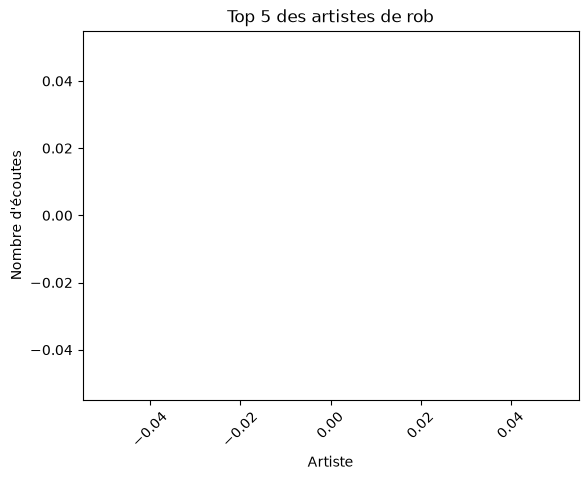

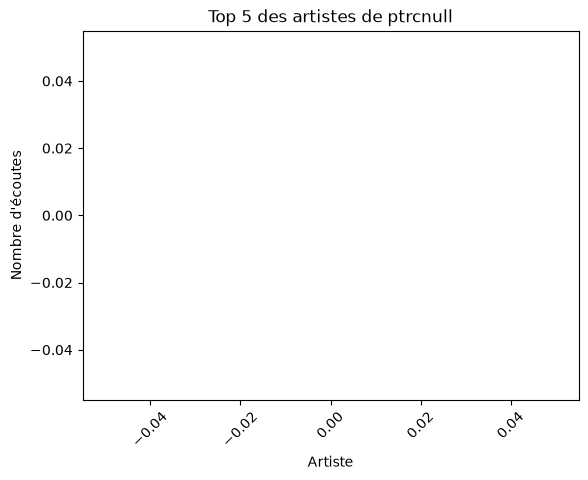

In [198]:
def plot_top_artists(user):
    user_top = top_artist[top_artist["user"] == user]

    plt.bar(user_top["artist"], user_top["listen_count"])

    plt.title(f"Top 5 des artistes de {user}")

    plt.xlabel("Artiste")

    plt.ylabel("Nombre d'écoutes")

    plt.xticks(rotation=45)

    plt.show()

plot_top_artists("rob")
plot_top_artists("ptrcnull")

# Quels sont les sons les plus écoutées

In [199]:
track_count = df.groupby(["user", "track"]).size().rename("listen_count").reset_index()

track_count.head()

,user,track,listen_count
0,BKILPATRICK11,A Milli,1
1,BKILPATRICK11,Ace of Hz,1
2,BKILPATRICK11,Age of Consent - 2015 Remaster,1
3,BKILPATRICK11,Alive (Nightmare),1
4,BKILPATRICK11,All + All Together,1


In [200]:
track_count_sorted = track_count.sort_values(["user","listen_count"], ascending=[True, False])
track_count_sorted.head()

,user,track,listen_count
28,BKILPATRICK11,Disco Inferno,2
32,BKILPATRICK11,Get Innocuous!,2
63,BKILPATRICK11,Only,2
0,BKILPATRICK11,A Milli,1
1,BKILPATRICK11,Ace of Hz,1


In [201]:
top_track = track_count_sorted.groupby("user").head(5)
top_track.head(10)

,user,track,listen_count
28,BKILPATRICK11,Disco Inferno,2
32,BKILPATRICK11,Get Innocuous!,2
63,BKILPATRICK11,Only,2
0,BKILPATRICK11,A Milli,1
1,BKILPATRICK11,Ace of Hz,1
97,BulBul280,$ex Appeal (feat. Too $hort),9
102,BulBul280,Ca$ino,9
100,BulBul280,Birds & the Bees,8
103,BulBul280,Circus Circus Free$tyle,8
105,BulBul280,Dramatic Girl (feat. Che Ecru),8


In [202]:
df.groupby("user")["track"].nunique()

user
BKILPATRICK11     97
BulBul280         22
Cedjuani          87
Censeii           94
CtrlAltRob        90
                  ..
xavlieury         94
ximonte           93
xz6977809856      91
youknowedo        81
zariel.zoralis    53
Name: track, Length: 140, dtype: int64

# Comment sont reparties les écoutes dans le temps

In [203]:
print(df["listened_at"].min())
print(df["listened_at"].max())

2025-10-24 18:26:41+00:00
2026-10-06 16:08:55+00:00


In [204]:
#mettre par goupe les user et leur temps, d'écoute. appliquer les fonctions mix et max
df.groupby("user")["listened_at"].agg(["min","max"])

,min,max
user,,
BKILPATRICK11,2026-10-04 19:26:56+00:00,2026-10-06 13:15:39+00:00
BulBul280,2026-03-29 23:23:50+00:00,2026-04-09 08:52:18+00:00
Cedjuani,2026-10-03 09:25:10+00:00,2026-10-05 23:51:34+00:00
Censeii,2026-09-29 07:40:22+00:00,2026-10-04 16:38:09+00:00
CtrlAltRob,2026-09-25 09:01:15+00:00,2026-10-06 06:13:53+00:00
...,...,...
xavlieury,2026-04-05 08:58:41+00:00,2026-04-07 13:49:28+00:00
ximonte,2026-09-26 09:13:54+00:00,2026-10-06 07:09:32+00:00
xz6977809856,2026-10-05 11:12:02+00:00,2026-10-06 13:49:43+00:00


In [205]:
#temps d'écoute
listening_period = df.groupby("user")["listened_at"].agg(["min","max"])


In [206]:
#chercher la durée d'écoutes
listening_period["duration"] = (listening_period["max"]) - (listening_period["min"])
listening_period

,min,max,duration
user,,,
BKILPATRICK11,2026-10-04 19:26:56+00:00,2026-10-06 13:15:39+00:00,1 days 17:48:43
BulBul280,2026-03-29 23:23:50+00:00,2026-04-09 08:52:18+00:00,10 days 09:28:28
Cedjuani,2026-10-03 09:25:10+00:00,2026-10-05 23:51:34+00:00,2 days 14:26:24
Censeii,2026-09-29 07:40:22+00:00,2026-10-04 16:38:09+00:00,5 days 08:57:47
CtrlAltRob,2026-09-25 09:01:15+00:00,2026-10-06 06:13:53+00:00,10 days 21:12:38
...,...,...,...
xavlieury,2026-04-05 08:58:41+00:00,2026-04-07 13:49:28+00:00,2 days 04:50:47
ximonte,2026-09-26 09:13:54+00:00,2026-10-06 07:09:32+00:00,9 days 21:55:38
xz6977809856,2026-10-05 11:12:02+00:00,2026-10-06 13:49:43+00:00,1 days 02:37:41


In [207]:
#créer une colone de date
df["date"] = df["listened_at"].dt.date

df.head()

,user,artist,artist_mbids,track,release,listened_at,date
0,phycoulog,Daichi Miura,None,FEVER,FEVER,2026-10-03 04:21:27+00:00,2026-10-03
1,phycoulog,Ngọt,None,LẦN CUỐI (đi bên em xót xa người ơi) [Explicit],LẦN CUỐI (đi bên em xót xa người ơi),2026-09-27 13:54:01+00:00,2026-09-27
2,phycoulog,Ngọt,None,LẦN CUỐI (đi bên em xót xa người ơi) [Explicit],LẦN CUỐI (đi bên em xót xa người ơi),2026-09-27 13:54:01+00:00,2026-09-27
3,phycoulog,Ngọt,[27a450da-ec68-47de-915f-f15f3750b10b],Mấy Khi,Gieo,2026-09-27 13:50:30+00:00,2026-09-27
4,phycoulog,Ngọt,[27a450da-ec68-47de-915f-f15f3750b10b],Mấy Khi,Gieo,2026-09-27 13:50:30+00:00,2026-09-27


In [208]:
#le nombre de d'ecoute par jours
df.groupby(["user","date"]).size()

user            date      
BKILPATRICK11   2026-10-04     58
                2026-10-05      1
                2026-10-06     41
BulBul280       2026-03-29     10
                2026-03-30     43
                             ... 
xz6977809856    2026-10-06     36
youknowedo      2026-07-18     34
                2026-07-19     63
                2026-07-20      3
zariel.zoralis  2026-10-06    100
Length: 804, dtype: int64

In [209]:
#le nombre de d'ecoute par jours
daily_listens = ( df.groupby(["user","date"])
                 .size().rename("listen_count")
                 .reset_index())
daily_listens

,user,date,listen_count
0,BKILPATRICK11,2026-10-04,58
1,BKILPATRICK11,2026-10-05,1
2,BKILPATRICK11,2026-10-06,41
3,BulBul280,2026-03-29,10
4,BulBul280,2026-03-30,43
...,...,...,...
799,xz6977809856,2026-10-06,36
800,youknowedo,2026-07-18,34
801,youknowedo,2026-07-19,63
802,youknowedo,2026-07-20,3


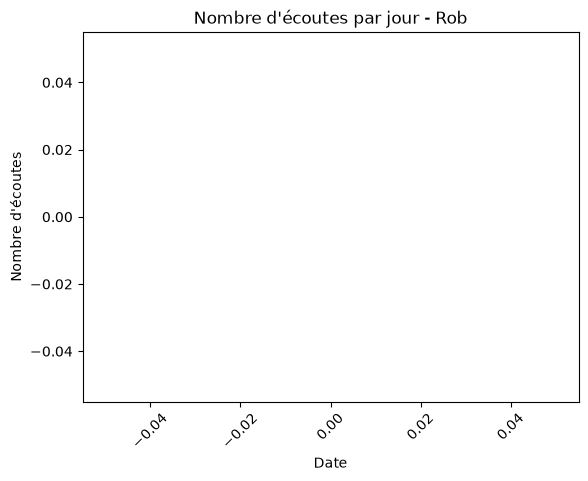

In [210]:
#graphique pour rob
rob_daily = daily_listens[daily_listens["user"] == "rob"]



plt.plot(rob_daily["date"], rob_daily["listen_count"],marker="o")
plt.title("Nombre d'écoutes par jour - Rob")

plt.xlabel("Date")

plt.ylabel("Nombre d'écoutes")

plt.xticks(rotation=45)

plt.show()

In [211]:
rob_daily[["date", "listen_count"]]


,date,listen_count


# Trouver des artistes en commun

In [212]:
#d'artiste écouté
artist_user_counts = df.groupby("artist")["user"].nunique()
artist_user_counts.sort_values(ascending=False).head(20)

artist
Kendrick Lamar    33
Drake             31
J. Cole           28
Frank Ocean       28
Kanye West        25
A$AP Rocky        24
Travis Scott      19
Baby Keem         18
Don Toliver       18
The Weeknd        17
Tame Impala       17
Zach Bryan        16
Daniel Caesar     16
EsDeeKid          15
Lil Uzi Vert      15
Olivia Dean       15
Mac Miller        15
Radiohead         15
Steve Lacy        15
Future            14
Name: user, dtype: int64

In [213]:
shared_artists = artist_user_counts[artist_user_counts >= 2]

print(len(shared_artists))

744


In [214]:
total_artists = df["artist"].nunique()

print(total_artists)

4661


In [215]:
shared_ratio = len(shared_artists) / total_artists

print(shared_ratio)

0.1596223986269041


In [216]:
#ensemble de valeur unique 
set(rob_artists)


{'B-Tribe',
 'Boards of Canada',
 'Bonobo, Jamila Woods',
 'Carbon Based Lifeforms',
 'Cell',
 'Christian Löffler',
 'Christian Löffler feat. Adna',
 'Christian Löffler feat. Shallou',
 'Christian Löffler, Adna',
 'Christian Löffler, Shallou',
 'Four Tet',
 'Kiasmos',
 'Orbital',
 'Republica',
 'Röyksopp',
 'Röyksopp feat. Astrid S',
 'Röyksopp feat. Jamie Irrepressible',
 'Röyksopp feat. Karen Harding',
 'Röyksopp feat. Pixx',
 'Röyksopp feat. Susanne Sundfør',
 'Röyksopp, Jamie Irrepressible',
 'Survivor',
 'The White Stripes',
 'The xx',
 'Tosca'}

In [217]:
#trouver les artistes commun entre deux utilisation 

common_artist = set(rob_artists) & set(ptrcnull_artists)
common_artist

set()

In [218]:
#test 

import requests

artist_mbid = "f93bac9e-b20a-403e-abc9-06a2fc151df1"

url = f"https://api.listenbrainz.org/1/stats/artist/{artist_mbid}/listeners"

response = requests.get(url)

print(response.status_code)

200


In [219]:
data = response.json()

print(data["payload"].keys())

dict_keys(['artist_mbid', 'artist_name', 'from_ts', 'last_updated', 'listeners', 'range', 'to_ts', 'total_listen_count', 'total_user_count'])


In [220]:
listeners = data["payload"]["listeners"]

print(listeners)

[{'listen_count': 5926, 'user_name': 'HeskeyHD'}, {'listen_count': 3617, 'user_name': 'madmusic7'}, {'listen_count': 3545, 'user_name': 'aaidoo'}, {'listen_count': 3408, 'user_name': 'myr2k'}, {'listen_count': 2915, 'user_name': 'Brookyi'}, {'listen_count': 2340, 'user_name': 'Myro'}, {'listen_count': 2063, 'user_name': 'ntgsykk'}, {'listen_count': 1902, 'user_name': 'shvv.'}, {'listen_count': 1781, 'user_name': 'ocean0479'}]


In [221]:
print(listeners[0]["user_name"])

HeskeyHD


In [222]:
for listener in listeners:
    print(listener["user_name"])

HeskeyHD
madmusic7
aaidoo
myr2k
Brookyi
Myro
ntgsykk
shvv.
ocean0479


In [223]:
data["payload"]["total_user_count"]
print(data["payload"]["total_user_count"])
print(len(listeners))

7705
9


In [224]:
user = "HeskeyHD"

url_similar = f"https://api.listenbrainz.org/1/user/{user}/similar-users"

response_similar = requests.get(url_similar)

print(response_similar.status_code)

200


In [225]:
similar_data = response_similar.json()

print(similar_data.keys())

dict_keys(['payload'])


In [226]:
print(similar_data["payload"])

[{'similarity': 0.5428780697187997, 'user_name': 'sheluvsxavier'}, {'similarity': 0.4082663480330726, 'user_name': 'jibbjibb'}, {'similarity': 0.38112560620303265, 'user_name': 'arculas20'}, {'similarity': 0.3174455959843871, 'user_name': 'jellycalvin'}, {'similarity': 0.291493454994371, 'user_name': 'jjbin'}, {'similarity': 0.275194129355157, 'user_name': 'MK4endy'}, {'similarity': 0.27379894788466846, 'user_name': 'eytangf'}, {'similarity': 0.26447378392988613, 'user_name': 'dancekevindance'}, {'similarity': 0.25968439076617944, 'user_name': 'krnxlsnt'}, {'similarity': 0.25899039719414824, 'user_name': 'pbertke'}, {'similarity': 0.25831506246596486, 'user_name': 'darhari'}, {'similarity': 0.2549173132969674, 'user_name': 'nikolaki'}, {'similarity': 0.23213464593244812, 'user_name': 'qbyz'}, {'similarity': 0.22423709432096722, 'user_name': 'Whozhighpitch'}, {'similarity': 0.21632822242248853, 'user_name': 'sconesmedia'}, {'similarity': 0.21389875316619492, 'user_name': 'rym21'}, {'sim

In [227]:
print(type(similar_data["payload"]))
print(type(similar_data["payload"][0]))
print(len(similar_data["payload"]))
print(len(similar_data["payload"][0]))

<class 'list'>
<class 'dict'>
25
2


In [228]:
similar_users = similar_data["payload"]
print(similar_users[0])
print(similar_users[0]["user_name"])
print(similar_users[0]["similarity"])
for user in similar_users:
    print(user["user_name"])

{'similarity': 0.5428780697187997, 'user_name': 'sheluvsxavier'}
sheluvsxavier
0.5428780697187997
sheluvsxavier
jibbjibb
arculas20
jellycalvin
jjbin
MK4endy
eytangf
dancekevindance
krnxlsnt
pbertke
darhari
nikolaki
qbyz
Whozhighpitch
sconesmedia
rym21
cisellis
p_ay904
aaarnold
HariSeldon0fe
AronP
space_invader85
senflummel
Unknown_Player
Aflutter5650


In [229]:
candidate_users = []

for user in similar_users:
    candidate_users.append(user["user_name"])

print(candidate_users)
print(len(candidate_users))

['sheluvsxavier', 'jibbjibb', 'arculas20', 'jellycalvin', 'jjbin', 'MK4endy', 'eytangf', 'dancekevindance', 'krnxlsnt', 'pbertke', 'darhari', 'nikolaki', 'qbyz', 'Whozhighpitch', 'sconesmedia', 'rym21', 'cisellis', 'p_ay904', 'aaarnold', 'HariSeldon0fe', 'AronP', 'space_invader85', 'senflummel', 'Unknown_Player', 'Aflutter5650']
25


In [230]:
unique_candidates = set(candidate_users)

print(len(candidate_users))
print(len(unique_candidates))

25
25


In [231]:
dave_top_users = []

for listener in listeners:
    dave_top_users.append(listener["user_name"])

print(dave_top_users)
print(len(dave_top_users))

['HeskeyHD', 'madmusic7', 'aaidoo', 'myr2k', 'Brookyi', 'Myro', 'ntgsykk', 'shvv.', 'ocean0479']
9


In [232]:
for user in dave_top_users[:2]:
    url = f"https://api.listenbrainz.org/1/user/{user}/similar-users"
    response = requests.get(url)

    print(user, response.status_code)

HeskeyHD 200
madmusic7 200


In [233]:
all_candidates = []

for user in dave_top_users:
    url = f"https://api.listenbrainz.org/1/user/{user}/similar-users"
    response = requests.get(url)

    similar_users = response.json()["payload"]

    for similar_user in similar_users:
        all_candidates.append({
        "source_user": user,
        "user_name": similar_user["user_name"],
        "similarity": similar_user["similarity"]
})
print(len(all_candidates))

200


In [234]:
print(all_candidates[0])

{'source_user': 'HeskeyHD', 'user_name': 'sheluvsxavier', 'similarity': 0.5428780697187997}


In [235]:
candidates_df = pd.DataFrame(all_candidates)

candidates_df

,source_user,user_name,similarity
0,HeskeyHD,sheluvsxavier,0.542878
1,HeskeyHD,jibbjibb,0.408266
2,HeskeyHD,arculas20,0.381126
3,HeskeyHD,jellycalvin,0.317446
4,HeskeyHD,jjbin,0.291493
...,...,...,...
195,ocean0479,BKILPATRICK11,0.217778
196,ocean0479,D33zz,0.215285
197,ocean0479,Sprout2569,0.215021
198,ocean0479,metedies,0.214912


In [236]:
candidate_counts = candidates_df["user_name"].value_counts()

candidate_counts.head(10)

user_name
CtrlAltRob        3
kitkattier        3
zariel.zoralis    3
ahmad subki       2
BulBul280         2
searchresult      2
connorads         2
kilem33221        2
dannyahums        2
axd40577          2
Name: count, dtype: int64

In [237]:
candidates_df[candidates_df["user_name"] == "CtrlAltRob"]

,source_user,user_name,similarity
45,madmusic7,CtrlAltRob,0.194827
67,aaidoo,CtrlAltRob,0.072170
140,ntgsykk,CtrlAltRob,0.159384


In [238]:
candidate_groups = candidates_df.groupby("user_name")
candidate_groups["similarity"].mean()

user_name
Aflutter5650      0.156457
AronP             0.185679
BKILPATRICK11     0.217778
BulBul280         0.226974
Cedjuani          0.142373
                    ...   
xz6977809856      0.073923
youknowedo        0.142015
yuhao88           0.158763
yyoooyy           0.150289
zariel.zoralis    0.190683
Name: similarity, Length: 181, dtype: float64

In [239]:
candidate_groups["similarity"].mean().sort_values(ascending=False).head(10)

user_name
sheluvsxavier    0.542878
jibbjibb         0.408266
arculas20        0.381126
gperkins         0.328315
almodammer       0.323842
Mango-Music      0.319652
jellycalvin      0.317446
aline.bento      0.315275
copperly         0.311540
jaymil0          0.304572
Name: similarity, dtype: float64

In [240]:
candidate_stats = candidate_groups["similarity"].agg(["count", "mean"])

candidate_stats.head()

,count,mean
user_name,,
Aflutter5650,1,0.156457
AronP,1,0.185679
BKILPATRICK11,1,0.217778
BulBul280,2,0.226974
Cedjuani,1,0.142373


In [241]:
candidate_stats.sort_values("count", ascending=False).head(10)

,count,mean
user_name,,
zariel.zoralis,3,0.190683
kitkattier,3,0.212369
CtrlAltRob,3,0.142127
Yeudio,2,0.195181
axd40577,2,0.209305
kilem33221,2,0.182399
Muziqa,2,0.228900
connorads,2,0.131147
izzo__,2,0.210853


In [242]:
ranked_candidates = candidate_stats.sort_values(
    ["count", "mean"],
    ascending=[False, False]
)

In [243]:
test_users = ranked_candidates.head(10).index.tolist()

print(test_users)

['kitkattier', 'zariel.zoralis', 'CtrlAltRob', 'Muziqa', 'BulBul280', 'izzo__', 'axd40577', 'notberrygud', 'ahmad subki', 'Yeudio']


In [244]:
df = pd.read_parquet("../data/processed/listens.parquet")

print(df.shape)
print(df["user"].nunique())
print(df["artist"].nunique())

(13973, 6)
140
4661


In [245]:
artist_user_counts = df.groupby("artist")["user"].nunique()

shared_artists = artist_user_counts[artist_user_counts >= 2]

print("Artistes partagés :", len(shared_artists))
print("Artistes totaux :", df["artist"].nunique())
print("Proportion :", len(shared_artists) / df["artist"].nunique())

Artistes partagés : 744
Artistes totaux : 4661
Proportion : 0.1596223986269041


In [246]:
print(">= 2 users :", (artist_user_counts >= 2).sum())
print(">= 3 users :", (artist_user_counts >= 3).sum())
print(">= 5 users :", (artist_user_counts >= 5).sum())
print(">= 10 users :", (artist_user_counts >= 10).sum())
print(">= 20 users :", (artist_user_counts >= 20).sum())

>= 2 users : 744
>= 3 users : 351
>= 5 users : 123
>= 10 users : 34
>= 20 users : 6


In [247]:
interactions = (
    df.groupby(["user", "artist"])
    .size()
    .reset_index(name = "count")

)

interactions.head()

print(interactions.shape)
print(interactions["count"].describe())

(6598, 3)
count    6598.000000
mean        2.117763
std         4.036695
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        86.000000
Name: count, dtype: float64


In [248]:
user_dates = df.groupby("user")["listened_at"].agg(["min","max"])

user_dates.head()

,min,max
user,,
BKILPATRICK11,2026-10-04 19:26:56+00:00,2026-10-06 13:15:39+00:00
BulBul280,2026-03-29 23:23:50+00:00,2026-04-09 08:52:18+00:00
Cedjuani,2026-10-03 09:25:10+00:00,2026-10-05 23:51:34+00:00
Censeii,2026-09-29 07:40:22+00:00,2026-10-04 16:38:09+00:00
CtrlAltRob,2026-09-25 09:01:15+00:00,2026-10-06 06:13:53+00:00


In [249]:
user_dates["duration"] = user_dates["max"] - user_dates["min"]
user_dates["duration"].describe()

count                        140
mean     13 days 16:22:12.185000
std      27 days 07:28:28.959000
min              0 days 02:29:19
25%       1 days 15:32:48.500000
50%              5 days 01:08:22
75%       9 days 22:27:48.250000
max            188 days 13:53:43
Name: duration, dtype: object

In [250]:
df_sorted = df.sort_values(["user", "listened_at"])
last_10 = df_sorted.groupby("user").tail(10)
test_unique_artists = last_10.groupby("user")["artist"].nunique()

test_unique_artists.describe()

count    140.000000
mean       6.814286
std        2.707798
min        1.000000
25%        4.750000
50%        7.000000
75%        9.000000
max       10.000000
Name: artist, dtype: float64

# TRAIN/ VALIDATION / Test

# Time Series

In [251]:
#separtion temporel
df_sorted = df.sort_values(
    by=["user", "listened_at"]
).reset_index(drop=True)

df_sorted.head(10)

,user,artist,artist_mbids,track,release,listened_at
0,BKILPATRICK11,A Tribe Called Quest,[9689aa5a-4471-4fb4-9721-07cecda0fa9f],Check the Rhime,The Low End Theory,2026-10-04 19:26:56+00:00
1,BKILPATRICK11,Kid Cudi,"[e0e1db18-f7ba-4dee-95ff-7ae8cf545460, c485632...",Pursuit of Happiness (Nightmare),The Boy Who Flew To The Moon (Vol. 1),2026-10-04 19:28:50+00:00
2,BKILPATRICK11,Kanye West,[164f0d73-1234-4e2c-8743-d77bf2191051],XTCY,XTCY,2026-10-04 19:33:42+00:00
3,BKILPATRICK11,Chip,None,"Diamond Rings (feat. Emeli Sandé, Kano & Wiley)",Diamond Rings,2026-10-04 19:36:37+00:00
4,BKILPATRICK11,Nas,[cfbc0924-0035-4d6c-8197-f024653af823],Michael & Quincy,King's Disease III,2026-10-04 19:39:46+00:00
5,BKILPATRICK11,Kendrick Lamar,[381086ea-f511-4aba-bdf9-71c753dc5077],DNA.,DAMN.,2026-10-04 19:42:35+00:00
6,BKILPATRICK11,A$AP Rocky,"[25b7b584-d952-4662-a8b9-dd8cdfbfeb64, 373a317...",Holy Ghost (feat. Joe Fox),AT.LONG.LAST.A$AP,2026-10-04 19:45:54+00:00
7,BKILPATRICK11,Lil Wayne,[ac9a487a-d9d2-4f27-bb23-0f4686488345],Hustler Musik,Tha Carter II,2026-10-04 19:49:05+00:00
8,BKILPATRICK11,Little Simz,[3cdb40fe-a63e-4bb9-b40d-17cda5f50979],Hollow,Lotus,2026-10-04 19:54:06+00:00
9,BKILPATRICK11,Little Simz,[3cdb40fe-a63e-4bb9-b40d-17cda5f50979],Only,Lotus,2026-10-04 19:56:59+00:00


In [252]:
#determiner la postion de chaque écoute
df_sorted["position"] = df_sorted.groupby("user").cumcount()

df_sorted[["user", "artist", "position"]].head(10)

,user,artist,position
0,BKILPATRICK11,A Tribe Called Quest,0
1,BKILPATRICK11,Kid Cudi,1
2,BKILPATRICK11,Kanye West,2
3,BKILPATRICK11,Chip,3
4,BKILPATRICK11,Nas,4
5,BKILPATRICK11,Kendrick Lamar,5
6,BKILPATRICK11,A$AP Rocky,6
7,BKILPATRICK11,Lil Wayne,7
8,BKILPATRICK11,Little Simz,8
9,BKILPATRICK11,Little Simz,9


In [253]:
#calculer le nombre d'écoute par utilisateur 
df_sorted["n_listens"] = (
    df_sorted.groupby("user")["artist"].transform("size")
)

df_sorted[["user", "artist", "position", "n_listens"]].head(10)

,user,artist,position,n_listens
0,BKILPATRICK11,A Tribe Called Quest,0,100
1,BKILPATRICK11,Kid Cudi,1,100
2,BKILPATRICK11,Kanye West,2,100
3,BKILPATRICK11,Chip,3,100
4,BKILPATRICK11,Nas,4,100
5,BKILPATRICK11,Kendrick Lamar,5,100
6,BKILPATRICK11,A$AP Rocky,6,100
7,BKILPATRICK11,Lil Wayne,7,100
8,BKILPATRICK11,Little Simz,8,100
9,BKILPATRICK11,Little Simz,9,100


In [254]:
#calcule des seuil de seuil de train/ validation/test/
df_sorted["train_end"] = (df_sorted["n_listens"] * 0.8).astype(int)

df_sorted["val_end"] = (df_sorted["n_listens"] * 0.9).astype(int)

df_sorted[
    ["user", "position", "n_listens", "train_end", "val_end"]
].head(10)

,user,position,n_listens,train_end,val_end
0,BKILPATRICK11,0,100,80,90
1,BKILPATRICK11,1,100,80,90
2,BKILPATRICK11,2,100,80,90
3,BKILPATRICK11,3,100,80,90
4,BKILPATRICK11,4,100,80,90
5,BKILPATRICK11,5,100,80,90
6,BKILPATRICK11,6,100,80,90
7,BKILPATRICK11,7,100,80,90
8,BKILPATRICK11,8,100,80,90
9,BKILPATRICK11,9,100,80,90


In [255]:
train_df = df_sorted[
    df_sorted["position"] < df_sorted["train_end"]
].copy()

val_df = df_sorted[
    (df_sorted["position"] >= df_sorted["train_end"]) &
    (df_sorted["position"] < df_sorted["val_end"])
].copy()

test_df = df_sorted[
    df_sorted["position"] >= df_sorted["val_end"]
].copy()

print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

Train : (11178, 10)
Validation : (1397, 10)
Test : (1398, 10)


In [256]:
train_last = train_df.groupby("user")["listened_at"].max()

val_first = val_df.groupby("user")["listened_at"].min()

print((train_last <= val_first).all())

True


In [257]:
val_last = val_df.groupby("user")["listened_at"].max()

test_first = test_df.groupby("user")["listened_at"].min()

print((val_last <= test_first).all())

True


In [258]:
train_ids = set(zip(train_df["user"], train_df["position"]))
val_ids = set(zip(val_df["user"], val_df["position"]))
test_ids = set(zip(test_df["user"], test_df["position"]))

print("Train / Validation :", len(train_ids & val_ids))
print("Train / Test :", len(train_ids & test_ids))
print("Validation / Test :", len(val_ids & test_ids))

Train / Validation : 0
Train / Test : 0
Validation / Test : 0


In [259]:
train_artists = (
    train_df.groupby("user")["artist"]
    .agg(set)
)

train_artists.head()

user
BKILPATRICK11    {The Royal Concept, Chip, Snoop Dogg, Dizzee R...
BulBul280        {Baby Keem, Kendrick Lamar, Momo Boyd, Baby Ke...
Cedjuani         {RAPROJECT SIX, Kazuma Kazuaki Mochizuki, Kurt...
Censeii          {Caroline Polachek, JID, Lorde, Travis Scott, ...
CtrlAltRob       {Knucks, Travis Scott, Kirbs, Blanco, Damzz, D...
Name: artist, dtype: object

In [260]:
val_artists = val_df.groupby("user")["artist"].agg(set)

new_val_artists = val_artists.combine(
    train_artists,
    lambda val, train: val.difference(train)
)

new_val_artists.head()

user
BKILPATRICK11              {Skepta, Radiohead, Tyler, The Creator}
BulBul280                                               {EsDeeKid}
Cedjuani         {WNTRBRK, Capella Grey, MIKE CLASSIC, SZA, Vil...
Censeii           {The 1975, Ski Mask the Slump God, Fred again..}
CtrlAltRob        {DONDA, XXXTENTACION, Pop Smoke, Eden, JACKBOYS}
Name: artist, dtype: object

In [261]:
n_new_val = new_val_artists.apply(len)

print(n_new_val.describe())

print(
    "Utilisateurs avec au moins une découverte :",
    (n_new_val > 0).sum()
)

count    140.000000
mean       3.935714
std        2.948505
min        0.000000
25%        1.000000
50%        4.000000
75%        6.000000
max       10.000000
Name: artist, dtype: float64
Utilisateurs avec au moins une découverte : 118


In [262]:
train_catalog = set(train_df["artist"])

print("Nombre d'artistes dans le catalogue :", len(train_catalog))

Nombre d'artistes dans le catalogue : 3967


In [263]:
evaluable_val_artists = new_val_artists.apply(
    lambda artists: artists.intersection(train_catalog)
)

n_evaluable_val = evaluable_val_artists.apply(len)

print(n_evaluable_val.describe())

print(
    "Utilisateurs évaluables :",
    (n_evaluable_val > 0).sum()
)


count    140.000000
mean       1.371429
std        1.601900
min        0.000000
25%        0.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: artist, dtype: float64
Utilisateurs évaluables : 85


In [264]:
train_val_df = pd.concat([train_df, val_df])

known_test_artists = (
    train_val_df.groupby("user")["artist"]
    .agg(set)
)

known_test_artists.head()

user
BKILPATRICK11    {Skepta, The Royal Concept, Chip, Snoop Dogg, ...
BulBul280        {EsDeeKid, Baby Keem, Kendrick Lamar, Momo Boy...
Cedjuani         {RAPROJECT SIX, Kazuma Kazuaki Mochizuki, Kurt...
Censeii          {Caroline Polachek, JID, Lorde, Travis Scott, ...
CtrlAltRob       {Knucks, Travis Scott, Kirbs, Eden, Blanco, Da...
Name: artist, dtype: object

In [265]:
test_artists = test_df.groupby("user")["artist"].agg(set)

new_test_artists = test_artists.combine(
    known_test_artists,
    lambda test, known: test.difference(known)
)

new_test_artists.head()

user
BKILPATRICK11    {Portishead, WZRD, Pusha T, ScHoolboy Q, Massi...
BulBul280        {JID, JID, Vince Staples, Offset, JID, JID, Cl...
Cedjuani         {Circles (Tiny Desk), AG Club & Jody Fontaine,...
Censeii          {Khalid, Lizzy McAlpine, Harry Styles, Troye S...
CtrlAltRob                                  {Tems, Maroon 5, EDEN}
Name: artist, dtype: object

In [266]:
test_catalog = set(train_val_df["artist"])

evaluable_test_artists = new_test_artists.apply(
    lambda artists: artists.intersection(test_catalog)
)

n_evaluable_test = evaluable_test_artists.apply(len)

print(n_evaluable_test.describe())

print(
    "Utilisateurs évaluables dans le Test :",
    (n_evaluable_test > 0).sum()
)

count    140.000000
mean       1.600000
std        1.635048
min        0.000000
25%        0.000000
50%        1.000000
75%        2.250000
max        7.000000
Name: artist, dtype: float64
Utilisateurs évaluables dans le Test : 95


# baseline
C'est une methode qui nous permet d'avoir des point de comparaison 

In [267]:
artist_popularity = (
    train_df.groupby("artist")
    .size()
    .sort_values(ascending=False)
)

artist_popularity.head(10)

artist
Zach Bryan       219
J. Cole          191
Olivia Dean      175
Drake            125
Daniel Caesar    104
Baby Keem        102
EsDeeKid          97
Mac Miller        80
Trippie Redd      72
ROSALÍA           67
dtype: int64

In [268]:
def recommend_popular(user, top_n =10):
    known = train_artists[user]
    recommendations = [

        artist
        for artist in artist_popularity.index
        if artist not in known
    
    ]
    return recommendations[:top_n]

recommend_popular("BKILPATRICK11")

['Zach Bryan',
 'Olivia Dean',
 'Drake',
 'Daniel Caesar',
 'EsDeeKid',
 'Mac Miller',
 'Trippie Redd',
 'ROSALÍA',
 'Frank Ocean',
 'Taylor Swift']

In [269]:
user = "BKILPATRICK11"

recommended = set(recommend_popular(user))

actual = evaluable_val_artists[user]

hits = recommended.intersection(actual)

print("Artistes recommandés :", recommended)
print("Artistes réellement découverts :", actual)
print("Artistes retrouvés :", hits)

Artistes recommandés : {'Daniel Caesar', 'Zach Bryan', 'EsDeeKid', 'Trippie Redd', 'Frank Ocean', 'ROSALÍA', 'Drake', 'Olivia Dean', 'Mac Miller', 'Taylor Swift'}
Artistes réellement découverts : {'Skepta', 'Radiohead', 'Tyler, The Creator'}
Artistes retrouvés : set()


In [270]:
def recall_at_k(recommended, actual):

    if len(actual) == 0:
        return None

    hits = set(recommended).intersection(actual)

    return len(hits) / len(actual)

recall_at_k(
    recommend_popular("BKILPATRICK11"),
    evaluable_val_artists["BKILPATRICK11"]
)

0.0

In [271]:
recall_scores = {}

for user in evaluable_val_artists.index:

    recommended = recommend_popular(user)
    actual = evaluable_val_artists[user]

    score = recall_at_k(recommended, actual)

    if score is not None:
        recall_scores[user] = score

print("Utilisateurs évalués :", len(recall_scores))
print("Recall@10 moyen :", sum(recall_scores.values()) / len(recall_scores))

Utilisateurs évalués : 85
Recall@10 moyen : 0.050980392156862744


In [272]:
import numpy as np

def dcg_at_k(recommended, actual):

    score = 0

    for i, artist in enumerate(recommended[:10], start=1):

        if artist in actual:
            score += 1 / np.log2(i + 1)

    return score

In [273]:
dcg_at_k(
    recommend_popular("BKILPATRICK11"),
    evaluable_val_artists["BKILPATRICK11"]
)

0

In [274]:
def ndcg_at_k(recommended, actual):

    if len(actual) == 0:
        return None

    dcg = dcg_at_k(recommended, actual)

    ideal_relevance = min(len(actual), 10)

    idcg = sum(
        1 / np.log2(i + 1)
        for i in range(1, ideal_relevance + 1)
    )

    return dcg / idcg

ndcg_at_k(
    recommend_popular("BKILPATRICK11"),
    evaluable_val_artists["BKILPATRICK11"]
)

np.float64(0.0)

In [275]:
ndcg_scores = {}

for user in evaluable_val_artists.index:

    recommended = recommend_popular(user)
    actual = evaluable_val_artists[user]

    score = ndcg_at_k(recommended, actual)

    if score is not None:
        ndcg_scores[user] = score

In [276]:
print("Utilisateurs évalués :", len(ndcg_scores))

print(
    "NDCG@10 moyen :",
    sum(ndcg_scores.values()) / len(ndcg_scores)
)

Utilisateurs évalués : 85
NDCG@10 moyen : 0.02349562609286546


# Clustering K-means

In [277]:
#contructions d'interactions

train_interactions = (
    train_df.groupby(["user", "artist"])
    .size()
    .reset_index(name="count")
)

print(train_interactions.shape)

train_interactions.head(10)


(5481, 3)


,user,artist,count
0,BKILPATRICK11,50 Cent,4
1,BKILPATRICK11,A Tribe Called Quest,1
2,BKILPATRICK11,A$AP Rocky,2
3,BKILPATRICK11,Adele,1
4,BKILPATRICK11,Baby Keem,1
5,BKILPATRICK11,Bentley,1
6,BKILPATRICK11,Blur,1
7,BKILPATRICK11,Busta Rhymes,1
8,BKILPATRICK11,Celeste,1
9,BKILPATRICK11,Chip,1


In [278]:
#creer une matrice car la methode pivot
user_artist_matrix = train_interactions.pivot(
    index="user",
    columns="artist",
    values="count"
).fillna(0)

print(user_artist_matrix.shape)

user_artist_matrix.iloc[:5, :10]


(140, 3967)


artist,"""DELUSIONS!"" Robert Pattinson Remix","""Profit Margins"" Alchemist",$NOT,$Not,$hyfromdatre,"$hyfromdatre, Apex3400",$uicideboy$,"$witchblade, lil sleepy","((( O ))), Please Wait",070 Shake
user,,,,,,,,,,
BKILPATRICK11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
BulBul280,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cedjuani,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Censeii,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
CtrlAltRob,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [279]:
#analyse de sparsité = proportion de 0 dans notre de matice d'interations
total_cells = user_artist_matrix.size

non_zero_cells = (user_artist_matrix != 0).sum().sum()

sparsity = 1 - (non_zero_cells / total_cells)

print("Nombre total de cellules :", total_cells)
print("Nombre de cellules non nulles :", non_zero_cells)
print("Sparsité :", sparsity)

Nombre total de cellules : 555380
Nombre de cellules non nulles : 5481
Sparsité : 0.9901310814217292


In [280]:
#normalisé les valeur en fonction du nombre d'écoutes
from sklearn.preprocessing import normalize

normalized_matrix = normalize(
    user_artist_matrix,
    norm="l2"
)

print(normalized_matrix.shape)
print(normalized_matrix[:2, :10])

(140, 3967)
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [281]:
norms = np.linalg.norm(normalized_matrix, axis=1)

print(norms[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters = 4, # nb de groupe créer
    random_state=42, #
    n_init=10 #nb d'initialisations et garde le meilleurs
)

clusters = kmeans.fit_predict(normalized_matrix)

print(clusters[:20])

[1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 2]


In [283]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()

print(cluster_counts)

0    99
1    14
2    11
3     8
4     8
Name: count, dtype: int64


In [284]:
user_clusters = pd.DataFrame({
    "user": user_artist_matrix.index,
    "cluster": clusters
})

user_clusters.head(10)

,user,cluster
0,BKILPATRICK11,1
1,BulBul280,0
2,Cedjuani,0
3,Censeii,0
4,CtrlAltRob,1
5,D33zz,0
6,Dogmo,0
7,Giganigga69,0
8,Gonca12,0
9,HHTHH,1


In [285]:
cluster_interactions = train_interactions.merge(
    user_clusters,
    on="user",
    how="left",
    validate="many_to_one"
)

cluster_interactions.head(10)

,user,artist,count,cluster
0,BKILPATRICK11,50 Cent,4,1
1,BKILPATRICK11,A Tribe Called Quest,1,1
2,BKILPATRICK11,A$AP Rocky,2,1
3,BKILPATRICK11,Adele,1,1
4,BKILPATRICK11,Baby Keem,1,1
5,BKILPATRICK11,Bentley,1,1
6,BKILPATRICK11,Blur,1,1
7,BKILPATRICK11,Busta Rhymes,1,1
8,BKILPATRICK11,Celeste,1,1
9,BKILPATRICK11,Chip,1,1


In [286]:

#on merge le data fram de user/cluster et celui des habitute muscale (user, artist, count)
cluster_interactions = train_interactions.merge(
    user_clusters,
    on="user",
    how="left",
    validate="many_to_one"
)

cluster_interactions.head(10)

,user,artist,count,cluster
0,BKILPATRICK11,50 Cent,4,1
1,BKILPATRICK11,A Tribe Called Quest,1,1
2,BKILPATRICK11,A$AP Rocky,2,1
3,BKILPATRICK11,Adele,1,1
4,BKILPATRICK11,Baby Keem,1,1
5,BKILPATRICK11,Bentley,1,1
6,BKILPATRICK11,Blur,1,1
7,BKILPATRICK11,Busta Rhymes,1,1
8,BKILPATRICK11,Celeste,1,1
9,BKILPATRICK11,Chip,1,1


In [287]:
cluster_popularity = (
    cluster_interactions
    .groupby(["cluster", "artist"])["count"]
    .sum()
    .reset_index()
)

cluster_popularity = cluster_popularity.sort_values(
    by=["cluster", "count"],
    ascending=[True, False]
)

cluster_popularity.groupby("cluster").head(10)

,cluster,artist,count
1987,0,Olivia Dean,174
607,0,Daniel Caesar,94
239,0,Baby Keem,74
1663,0,Mac Miller,69
2141,0,ROSALÍA,67
2738,0,Trippie Redd,63
2524,0,Taylor Swift,56
636,0,Dave,52
1292,0,Jon Bellion,51
1713,0,Madonna,48


In [288]:
#verfier l'attributions des écoutes des utilisateurs à chaque cluster 
cluster_artist_users = (
    cluster_interactions
    .groupby(["cluster", "artist"])["user"]
    .nunique()
    .reset_index(name="n_users")
)

cluster_artist_users = cluster_artist_users.sort_values(
    by=["cluster", "n_users"],
    ascending=[True, False]
)

cluster_artist_users.groupby("cluster").head(10)

,cluster,artist,n_users
1423,0,Kendrick Lamar,19
727,0,Drake,18
1381,0,Kanye West,16
65,0,A$AP Rocky,15
890,0,Frank Ocean,15
607,0,Daniel Caesar,12
1987,0,Olivia Dean,12
2516,0,Tame Impala,12
2726,0,Travis Scott,12
2524,0,Taylor Swift,11


# recomandation par cluster

In [289]:
cluster_top_artists = (
    cluster_artist_users
    .groupby("cluster")["artist"]
    .apply(list)
    .to_dict()
)

print(cluster_top_artists[1][:10])


['J. Cole', 'Drake', 'Baby Keem', 'Don Toliver', 'Kendrick Lamar', 'Travis Scott', 'Eminem', 'Freddie Gibbs', 'Gunna', 'JID']


In [290]:
user_to_cluster = dict(
    zip(user_clusters["user"], user_clusters["cluster"])
)

print(user_to_cluster["BKILPATRICK11"])

1


In [291]:
#fonction de recommandation
def recommend_kmeans(user, top_n=10):

    cluster = user_to_cluster[user]

    known = train_artists[user]

    recommendations = [
        artist
        for artist in cluster_top_artists[cluster]
        if artist not in known
    ]

    return recommendations[:top_n]

print("K-Means :", recommend_kmeans("BKILPATRICK11"))

print("Popularité :", recommend_popular("BKILPATRICK11"))

K-Means : ['Drake', 'Don Toliver', 'Travis Scott', 'Freddie Gibbs', 'Gunna', 'JID', 'Vince Staples', 'YG', 'Yeat', '21 Savage']
Popularité : ['Zach Bryan', 'Olivia Dean', 'Drake', 'Daniel Caesar', 'EsDeeKid', 'Mac Miller', 'Trippie Redd', 'ROSALÍA', 'Frank Ocean', 'Taylor Swift']


In [292]:
kmeans_recall_scores = {}
kmeans_ndcg_scores = {}

for user in evaluable_val_artists.index:

    recommended = recommend_kmeans(user)
    actual = evaluable_val_artists[user]

    recall = recall_at_k(recommended, actual)
    ndcg = ndcg_at_k(recommended, actual)

    if recall is not None:
        kmeans_recall_scores[user] = recall
        kmeans_ndcg_scores[user] = ndcg


print("Utilisateurs évalués :", len(kmeans_recall_scores))

print(
    "Recall@10 moyen :",
    sum(kmeans_recall_scores.values()) / len(kmeans_recall_scores)
)

print(
    "NDCG@10 moyen :",
    sum(kmeans_ndcg_scores.values()) / len(kmeans_ndcg_scores)
)

Utilisateurs évalués : 85
Recall@10 moyen : 0.07941176470588235
NDCG@10 moyen : 0.05768564480988467


# test pour plusieurs valeu de k

In [293]:
k_values = [2, 3, 4, 5, 6, 8, 10]

kmeans_results = []

print(k_values)

[2, 3, 4, 5, 6, 8, 10]


In [ ]:
for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(normalized_matrix) #entraine le model et attribu un cluster a chaque user 

    print(f"K={k} :", np.bincount(labels))

K=2 : [ 12 128]
K=3 : [76 12 52]
K=4 : [36 31 12 61]
K=5 : [99 14 11  8  8]
K=6 : [33 29 29 10 27 12]
K=8 : [10 10 44 21 16 12  9 18]
K=10 : [10 10 35 20 15 12  9 13 10  6]


In [ ]:
def recommend_kmeans_tuned(user, user_clusters, top_artists, top_n=10):

    cluster = user_clusters[user]

    known = train_artists[user]

    recommendations = [
        artist
        for artist in top_artists[cluster]
        if artist not in known
    ]

    return recommendations[:top_n]

recommend_kmeans_tuned(
    "BKILPATRICK11",
    user_to_cluster,
    cluster_top_artists
)

In [311]:
kmeans_results = []
for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(normalized_matrix)

    temp_user_clusters = pd.DataFrame({
        "user": user_artist_matrix.index,
        "cluster": labels
    })

    temp_interactions = train_interactions.merge(
        temp_user_clusters,
        on="user",
        how="left",
        validate="many_to_one"
    )

    temp_popularity = (

        temp_interactions

        .groupby(["cluster", "artist"])["user"]

        .nunique()

        .reset_index(name="n_users")

    )

    temp_popularity = temp_popularity.sort_values(

        by=["cluster", "n_users"],

        ascending=[True, False]

    )

    temp_top_artists = (

        temp_popularity

        .groupby("cluster")["artist"]

        .apply(list)

        .to_dict()
    )

    temp_user_to_cluster = dict(
        zip(
            temp_user_clusters["user"],
            temp_user_clusters["cluster"]
        )
    )
        # Évaluer les recommandations pour chaque utilisateur
    recall_scores_k = []
    ndcg_scores_k = []

    for user in evaluable_val_artists.index:

        actual = evaluable_val_artists[user]

        if len(actual) == 0:
            continue

        recommended = recommend_kmeans_tuned(
            user,
            temp_user_to_cluster,
            temp_top_artists
        )

        recall_scores_k.append(
            recall_at_k(recommended, actual)
        )

        ndcg_scores_k.append(
            ndcg_at_k(recommended, actual)
        )

    print(f"K={k} :", len(recall_scores_k))

    
    mean_recall = np.mean(recall_scores_k)
    mean_ndcg = np.mean(ndcg_scores_k)

    kmeans_results.append({
        "k": k,
        "recall@10": mean_recall,
        "ndcg@10": mean_ndcg
    })
    
    
    

K=2 : 85
K=3 : 85
K=4 : 85
K=5 : 85
K=6 : 85
K=8 : 85
K=10 : 85


In [312]:
results_df = pd.DataFrame(kmeans_results)

results_df

,k,recall@10,ndcg@10
0,2,0.107843,0.062665
1,3,0.116078,0.075231
2,4,0.106387,0.066514
3,5,0.079412,0.057686
4,6,0.093641,0.057380
5,8,0.071961,0.037814
6,10,0.080196,0.047886


In [313]:
best_k = results_df.loc[
    results_df["ndcg@10"].idxmax(),
    "k"
]

print("Meilleur nombre de clusters :", best_k)

Meilleur nombre de clusters : 3


# Test XG BOOST 

In [5]:
import pandas as pd

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "listens.parquet"

df = pd.read_parquet(DATA_PATH)

print(df.shape)
display(df.head())

(22373, 6)


,user,artist,artist_mbids,track,release,listened_at
0,lakarari,Kanye West,[164f0d73-1234-4e2c-8743-d77bf2191051],Heaven and Hell,Donda,2026-04-18 04:11:03+00:00
1,lakarari,Frankie III,None,giardini pesche,Canzoni di Kart,2026-04-17 22:24:46+00:00
2,lakarari,Frankie III,None,molo delfino,Canzoni di Kart,2026-04-17 22:06:51+00:00
3,lakarari,Frankie III,None,montagna cioccolato,Canzoni di Kart,2026-04-17 22:04:31+00:00
4,lakarari,Frankie III,None,giardino cielo,Canzoni di Kart,2026-04-17 22:01:14+00:00


In [6]:
print("Total listens:", len(df))

print("Unique users:", df["user"].nunique())

print("Unique artists:", df["artist"].nunique())

Total listens: 22373
Unique users: 224
Unique artists: 6413
